# 1 | Imports, Cached Data, Prices

There are two fetch scripts to collect fragmented data from EDGAR and Wikipedia revisions:

- __Wikipeida Revisions:__ Revision history of the S&P 500 constituents allow the tracking of changes in the index.
Additions and removals to the index over the fetched period are consolidated via monthly revisions over the Wikipedia API. Wikipedia also lists the GICS sectors of constituents and that information is used to identify changes in classification over time.
- __EDGAR Facts:__ EDGAR is constructed such that facts are retrieved by CIK (Ticker). Collecting facts over a wide date range for ~100 constituents is therefore a bulky request per CIK. The process is executed beforehand and cached into a csv to avoid potential rate limits on repeated runs of the notebook.

Where a `# !python ...` comment is seen, removing the comment (`#`) will execute the script name following the command and start a fetch.
Prices are fetched fast with threads via the `yfinance` library and rate limits are 2000/hour. Those are not cached and are fetched on every run of the notebook.

In [95]:
# Imports
import yfinance as yf

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import logging
from typing import cast

logging.getLogger("yfinance").setLevel(logging.CRITICAL)

In [96]:
# Point-in-time membership and GICS sector, monthly snapshots

# !python fetch_constituents.py
members = pd.read_csv("data/constituents_pit.csv", parse_dates=["snapshot"])
it_members = members.loc[members["sector"] == "Information Technology"]

universe = sorted(it_members["ticker"].unique())  # names to download
it_at = it_members.groupby("snapshot")["ticker"].apply(frozenset)  # membership as-of

print(
    f"{len(universe)} names across {len(it_at)} snapshots, "
    f"{it_at.map(len).min()}-{it_at.map(len).max()} in sector at a time"
)

97 names across 50 snapshots, 64-76 in sector at a time


In [97]:
# Load the trimmed EDGAR facts
# !python fetch_edgar.py
facts = pd.read_csv(
    "data/edgar_facts_trimmed.csv", parse_dates=["start", "end", "filed"]
)

In [98]:
# Price data, "Adj Close" is split and dividend adjusted, "Close" is not
pinfo = cast(
    pd.DataFrame,
    yf.download(
        universe,
        start="2021-10-01",
        end="2026-10-01",
        actions=True,
        threads=True,
        auto_adjust=False,
        ignore_tz=True,
        progress=False,
    ),
)

In [99]:
etf = cast(
    pd.DataFrame,
    yf.download(
        "XLK",
        start="2021-10-01",
        end="2026-10-01",
        threads=True,
        auto_adjust=True,  # "Close" with adj=True is "Adj Close"
        ignore_tz=True,
        progress=False,
    ),
)

In [100]:
irx = cast(
    pd.DataFrame,
    yf.download(
        "^IRX",
        start="2021-10-01",
        end="2026-10-01",
        threads=True,
        auto_adjust=True,  # "Close" with adj=True is "Adj Close"
        ignore_tz=True,
        progress=False,
    ),
)

BILL_DAYS = 91  # ^IRX tracks the 13-week bill

# rate accrued daily, filling weekends produce a ACT/365 investment yield.
# Alternative is using 252 trading-days, functionally equivalent but not exact.
disc = (irx["Close"].squeeze() / 100.0).reindex(pinfo.index).ffill()
irx_yld = 365.0 * disc / (360.0 - disc * BILL_DAYS)

days = pinfo.index.to_series().diff().dt.days.fillna(1).astype(int)
rf = irx_yld.shift(1) * days / 365.0  # prior close is the rate that accrues into t

## 2 | Quarterly Flows

A trailing-twelve-month figure needs four non-overlapping quarters. 
FY is reported instead of Q4 and differencing the first three quarters recovers the fourth quarter.

In [ ]:
TAGS = ["NetIncomeLoss", "ProfitLoss", "OperatingIncomeLoss"]
QUARTER_DAYS = (80, 100)

dur = facts.loc[facts["tag"].isin(TAGS)].copy()
dur = (
    dur.loc[dur["start"].notna()]
    .sort_values("filed")
    .drop_duplicates(["ticker", "tag", "start", "end"], keep="first")
    .sort_values(["ticker", "tag", "start", "end"])
)

ladder = dur.groupby(["ticker", "tag", "start"], sort=False)
prev_end = ladder["end"].shift(1)
prev_val = ladder["val"].shift(1)
prev_filed = ladder["filed"].shift(1)

q = pd.DataFrame(
    {
        "ticker": dur["ticker"],
        "tag": dur["tag"],
        "qstart": prev_end.fillna(dur["start"] - pd.Timedelta(days=1))
        + pd.Timedelta(days=1),
        "qend": dur["end"],
        "val": dur["val"] - prev_val.fillna(0.0),
        # a differenced quarter is knowable only once both of its rows are filed
        "filed": pd.concat([dur["filed"], prev_filed], axis=1).max(axis=1),
        "source": np.where(prev_end.isna(), "reported", "differenced"),
    }
)
q["days"] = (q["qend"] - q["qstart"]).dt.days + 1
q = q.loc[q["days"].between(*QUARTER_DAYS)]

# a standalone row and the ladder computation can both yield the
# same quarter. (See below for the distribution of differences)
quarters = (
    q.sort_values(["filed", "days"])
    .drop_duplicates(["ticker", "tag", "qend"], keep="first")
    .sort_values(["ticker", "tag", "qend"])
    .reset_index(drop=True)
)

both = q.groupby(["ticker", "tag", "qend"])["val"].agg(["size", "nunique"])
print(f"{len(quarters)} quarters over {quarters['ticker'].nunique()} tickers")
print(quarters["source"].value_counts())
print(
    f"{((both['size'] > 1) & (both['nunique'] > 1)).sum()} quarters where the two routes disagree"
)

4387 quarters over 97 tickers
source
differenced    3120
reported       1267
Name: count, dtype: int64
100 quarters where the two routes disagree


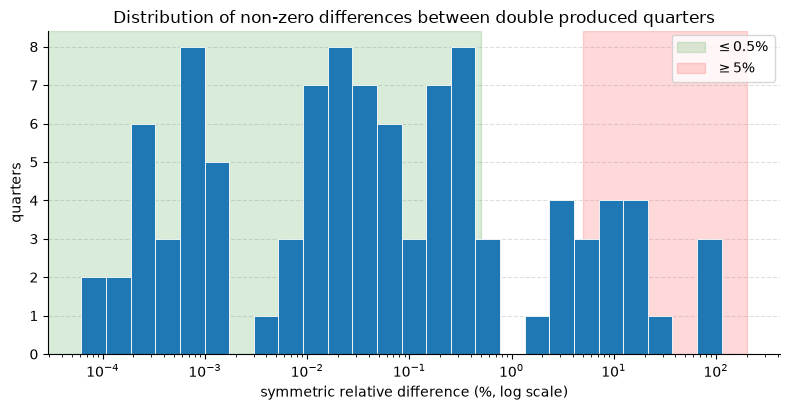

In [ ]:
# Where a standalone row and the ladder both yield a quarter, how far apart are they?
both = q.groupby(["ticker", "tag", "qend"])["val"].agg(lo="min", hi="max", n="size")
dis = both.loc[(both["n"] > 1) & (both["lo"] != both["hi"])].copy()
dis["pct"] = 100 * (dis["hi"] - dis["lo"]) / dis[["lo", "hi"]].abs().max(axis=1)

bins = np.logspace(np.log10(dis["pct"].min()), np.log10(dis["pct"].max()), 28)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(dis["pct"], bins=bins, edgecolor="white", linewidth=0.6)
ax.set_xscale("log")
ax.set_xlabel("symmetric relative difference (%, log scale)")
ax.set_ylabel("quarters")
ax.set_title(f"Distribution of non-zero differences between double produced quarters")

for x, y, color, label in (
    (0.0, 0.5, "green", r"$\leq 0.5\%$"),
    (5.0, 200.0, "red", r"$\geq 5\%$"),
):
    ax.axvspan(x, y, color=color, alpha=0.15, label=label, zorder=0)

ax.grid(axis="y", color="gray", alpha=0.25, linewidth=0.8, linestyle="--")
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.legend(loc=(0.85, 0.8))
fig.tight_layout()
plt.show()

## 3 | Trailing Twelve Months

Rolling sums of 4 quarter flows to get continuous TTMs.

In [ ]:
TTM_SPAN = (350, 380)

ttm = quarters.sort_values(["ticker", "tag", "qend"]).copy()
year = ttm.groupby(["ticker", "tag"], sort=False)

ttm["ttm"] = sum(year["val"].shift(k) for k in range(4))
ttm["knowable"] = pd.concat([year["filed"].shift(k) for k in range(4)], axis=1).max(
    axis=1
)
ttm["wstart"] = year["qstart"].shift(3)
ttm["span"] = (ttm["qend"] - ttm["wstart"]).dt.days + 1

# a spinoff's first filings carry carve-out quarters for a business that was not listed yet
listed = (
    pinfo["Adj Close"].apply(lambda s: s.first_valid_index()).astype("datetime64[us]")
)
listed = listed.loc[listed > pinfo.index[0]]
standalone = ~ttm["ticker"].isin(listed.index) | (
    ttm["wstart"] >= ttm["ticker"].map(listed)
)
contiguous = ttm["span"].between(*TTM_SPAN)

dropped = ttm.loc[contiguous & ~standalone, "ticker"]
ttm = ttm.loc[contiguous & standalone, ["ticker", "tag", "qend", "ttm", "knowable"]]

print(f"{len(ttm)} ttm observations over {ttm['ticker'].nunique()} tickers")
print(ttm.groupby("tag").size().to_string())
print(f"{len(dropped)} windows dropped as pre-listing: {dict(dropped.value_counts())}")

3677 ttm observations over 96 tickers
tag
NetIncomeLoss          1552
OperatingIncomeLoss    1547
ProfitLoss              578
18 windows dropped as pre-listing: {'SNDK': np.int64(13), 'Q': np.int64(5)}


## 4 | Point-in-Time Panel

Every fundamental is an as-of lookup gated on `filed` (date of publication).

Two balance-sheet items need a precedence rule. Short-term
investments are tagged under any of seven names and several tag more than one. The first that reports wins.
`LongTermDebt` is total while the other two are components. Total is preferred when available, sum of components act as the fallback.

In [131]:
TEST = ("2023-10-01", "2026-09-30")

# yfinance returns second-resolution stamps and the EDGAR columns parse to microsecond,
# which merge_asof will not join across
trading = pinfo.index.as_unit("us")
rebal = pd.DatetimeIndex(
    [trading[trading.searchsorted(d)] for d in pd.date_range(*TEST, freq="MS")]
)

pairs = pd.concat(
    [
        pd.DataFrame(
            {"date": t, "ticker": sorted(it_at.loc[it_at.index <= t].iloc[-1])}
        )
        for t in rebal
    ],
    ignore_index=True,
)


def asof(src, col):
    s = (
        src.sort_values("filed")
        .drop_duplicates(["ticker", "end"], keep="first")[["ticker", "filed", "val"]]
        .rename(columns={"val": col, "filed": f"{col}_filed"})
    )
    return pd.merge_asof(pairs, s, left_on="date", right_on=f"{col}_filed", by="ticker")


CASH = "CashAndCashEquivalentsAtCarryingValue"
SECURITIES = [
    "ShortTermInvestments",
    "MarketableSecuritiesCurrent",
    "AvailableForSaleSecuritiesDebtSecuritiesCurrent",
    "DebtSecuritiesAvailableForSaleExcludingAccruedInterestCurrent",
    "OtherShortTermInvestments",
    "HeldToMaturitySecuritiesCurrent",
    "AvailableForSaleSecuritiesCurrent",
]
DEBT = ["LongTermDebt", "LongTermDebtNoncurrent", "LongTermDebtCurrent"]

inst = facts.loc[facts["start"].isna()]
bs = pairs.copy()
for tag in [CASH, *SECURITIES, *DEBT]:
    bs[tag] = asof(inst.loc[inst["tag"] == tag], tag)[tag]

bs["securities"] = bs[SECURITIES].bfill(axis=1).iloc[:, 0]
bs["debt"] = bs["LongTermDebt"].fillna(
    bs["LongTermDebtNoncurrent"].fillna(0.0) + bs["LongTermDebtCurrent"].fillna(0.0)
)
bs["net_cash"] = bs[CASH] + bs["securities"].fillna(0.0)

no_debt = bs[DEBT].isna().all(axis=1)
print(
    f"{len(rebal)} rebalance dates, {len(pairs)} name-dates, {pairs['ticker'].nunique()} distinct names"
)
print(
    f"cash {bs[CASH].notna().mean():.1%}, securities {bs['securities'].notna().mean():.1%} of name-dates"
)
print(f"{no_debt.mean():.1%} of name-dates report no debt")

36 rebalance dates, 2463 name-dates, 81 distinct names
cash 98.2%, securities 68.0% of name-dates
14.0% of name-dates report no debt


## 5 | Valuation Yields

Market capitalisation needs the traded share count against a price on the same basis.
`Close` is split-adjusted and carries no dividend adjustment.
Restating onto one basis is also what makes a filer comparable against itself, to catch filing errors. (See the comment below)
Two errors leaked into screen selection which made the problem impossible to ignore.

In [ ]:
close = pinfo["Close"].ffill()

# yfinance returns no actions block for delisted names
# align indices with a 1.0 fill
splits = (
    pinfo["Stock Splits"].reindex(columns=close.columns).fillna(1.0).replace(0.0, 1.0)
)
clog = np.log(splits).cumsum()
col = close.columns.get_indexer(pairs["ticker"])
assert (col >= 0).all(), "a member is missing from the price frame"


def share_obs(src):
    s = src[["ticker", "end", "filed", "val"]].copy()
    c = close.columns.get_indexer(s["ticker"])
    row = np.clip(
        trading.searchsorted(s["filed"], side="right") - 1, 0, len(trading) - 1
    )
    s["val"] = s["val"].astype(float) * np.exp(
        clog.to_numpy()[-1, c] - clog.to_numpy()[row, c]
    )

    # a filer's own counts only compare once restated onto one split basis.
    # NTAP dropped a digit in 2024-02
    # TER's diluted avg is ~1000x off in 2023-10.
    return s.loc[
        (s["val"] / s.groupby("ticker")["val"].transform("median")).between(1 / 3, 3)
    ]


def ttm_at(tag, name):
    s = ttm.loc[ttm["tag"] == tag].sort_values("knowable")[
        ["ticker", "knowable", "ttm"]
    ]
    return pd.merge_asof(
        pairs,
        s.rename(columns={"ttm": name}),
        left_on="date",
        right_on="knowable",
        by="ticker",
    )[name]


# the cover count is dimensioned by share class for multi-class filers.
# EDGAR drops that, diluted avg subs in where needed.
cover = inst.loc[inst["tag"] == "EntityCommonStockSharesOutstanding"]
wa = facts.loc[facts["tag"] == "WeightedAverageNumberOfDilutedSharesOutstanding"]
wa = wa.loc[((wa["end"] - wa["start"]).dt.days + 1).between(*QUARTER_DAYS)]

cover_ok, wa_ok = share_obs(cover), share_obs(wa)
a, b = asof(cover_ok, "cover"), asof(wa_ok, "wa")

metrics = pairs.copy()
metrics["price"] = close.to_numpy()[trading.get_indexer(pairs["date"]), col]
metrics["shares"] = a["cover"].fillna(b["wa"])
metrics["mcap"] = metrics["price"] * metrics["shares"]
metrics["ev"] = metrics["mcap"] + bs["debt"] - bs["net_cash"]
metrics["ebit"] = ttm_at("OperatingIncomeLoss", "ebit")
metrics["earnings"] = ttm_at("NetIncomeLoss", "earnings").fillna(
    ttm_at("ProfitLoss", "earnings")
)

metrics["ebit_ev"] = metrics["ebit"] / metrics["ev"]
metrics["ep"] = metrics["earnings"] / metrics["mcap"]

per_date = metrics.groupby("date")[["ebit_ev", "ep"]].count()
print(
    f"{metrics[['ebit_ev', 'ep']].notna().all(axis=1).sum()} of {len(metrics)} name-dates carry both yields"
)
print(
    f"{len(cover) - len(cover_ok)} cover and {len(wa) - len(wa_ok)} diluted rows rejected as implausible"
)
print(
    f"per rebalance: EBIT/EV {per_date['ebit_ev'].min()}-{per_date['ebit_ev'].max()}, "
    f"E/P {per_date['ep'].min()}-{per_date['ep'].max()}"
)
print(
    f"{(metrics['ebit'] < 0).sum()} name-dates on negative trailing EBIT, "
    f"{(metrics['earnings'] < 0).sum()} on negative trailing earnings"
)

2274 of 2463 name-dates carry both yields
1 cover and 2 diluted rows rejected as implausible
per rebalance: EBIT/EV 58-70, E/P 61-73
112 name-dates on negative trailing EBIT, 113 on negative trailing earnings


## 6 | The Screen

Five cheapest long and five dearest short at each rebalance, ranked within the sector on one
yield at a time. Three variants run side by side:

| screen | ranks on | universe |
| --- | --- | --- |
| `ebit_ev` | EBIT / EV | every name carrying the yield |
| `ep` | earnings / market cap | every name carrying the yield |
| `ebit_ev_pos` | EBIT / EV | names with positive trailing EBIT |

Positive EBIT case is a control for the short leg being (incidentally) selected on profitability. 

In [ ]:
SCREENS = {
    "ebit_ev": ("ebit_ev", None),
    "ep": ("ep", None),
    "ebit_ev_pos": ("ebit_ev", "ebit"),  # universe cut at selection, not in the panel
}


def select(metric, positive=None):
    d = metrics.dropna(subset=[metric])
    if positive:
        d = d.loc[d[positive] > 0]

    rank = d.groupby("date")[metric].rank(method="first", ascending=False)
    n = d.groupby("date")[metric].transform("size")
    side = pd.Series(pd.NA, index=d.index, dtype="object")
    side[rank <= 5] = "long"
    side[rank > n - 5] = "short"

    out = d.loc[
        side.notna(), ["date", "ticker", "mcap", "ev", "ebit", "earnings"]
    ].copy()
    out["yield"] = d.loc[side.notna(), metric]
    out["side"] = side.dropna()
    return out


picks = pd.concat(
    [
        select(metric, pos).assign(screen=name)
        for name, (metric, pos) in SCREENS.items()
    ],
    ignore_index=True,
)

print(f"{len(picks)} selections, 5 a side over {metrics['date'].nunique()} rebalances")
base = (
    picks.loc[picks["screen"] == "ebit_ev"]
    .groupby(["date", "side"])["ticker"]
    .apply(frozenset)
)
for name in ("ep", "ebit_ev_pos"):
    alt = (
        picks.loc[picks["screen"] == name]
        .groupby(["date", "side"])["ticker"]
        .apply(frozenset)
    )
    shared = pd.concat([base, alt], axis=1, keys=["a", "b"]).dropna()
    shared["n"] = [len(x & y) for x, y in zip(shared["a"], shared["b"])]
    agree = ", ".join(
        f"{s} {shared.xs(s, level='side')['n'].mean():.2f}" for s in ("long", "short")
    )
    print(f"Average selection overlap out of 5 ({name} vs ebit_ev): {agree}")

1080 selections, 5 a side over 36 rebalances
Average selection overlap out of 5 (ep vs ebit_ev): long 3.06, short 4.17
Average selection overlap out of 5 (ebit_ev_pos vs ebit_ev): long 5.00, short 2.06


## 7 | Beta and the Hedge

A year of daily excess returns against XLK gives each holding its beta.
The hedge is the negated net beta of the long-short.

In [ ]:
BETA_WIN = 252

exc = pinfo["Adj Close"].pct_change().sub(rf, axis=0)
exm = etf["Close"].squeeze().pct_change() - rf


def betas_at(end):
    w = slice(max(0, end - BETA_WIN), end)
    x, y = exm.iloc[w], exc.iloc[w]
    # beta = cov(y, x) / var(x) -> Standard OLS with ETF regressor.
    return y.apply(lambda s: s.cov(x) / x[s.notna()].var())


# window ends the day before the rebalance; nothing is estimated on the trade date
beta = pd.DataFrame({t: betas_at(trading.searchsorted(t)) for t in rebal}).T.stack()
beta.index.names = ["date", "ticker"]

book = picks.merge(beta.rename("beta").reset_index(), on=["date", "ticker"], how="left")
book["w"] = np.where(book["side"] == "long", 1.0, -1.0) / 5

# XLK's beta is 1 and the hedge is the negated net
hedge = book.groupby(["screen", "date"]).apply(
    lambda d: pd.Series(
        {
            "gross_stock": d["w"].abs().sum(),
            "net_stock": d["w"].sum(),
            "beta_long": d.loc[d["side"] == "long", "beta"].mean(),
            "beta_short": d.loc[d["side"] == "short", "beta"].mean(),
            "net_beta": (d["w"] * d["beta"]).sum(),
        }
    ),
    include_groups=False,
)
hedge["xlk"] = -hedge["net_beta"]
hedge["net_dollar"] = hedge["net_stock"] + hedge["xlk"]
hedge["gross"] = hedge["gross_stock"] + hedge["xlk"].abs()

print(
    f"beta on {BETA_WIN}d excess returns vs XLK, {book['beta'].notna().sum()} of {len(book)} selections"
)
print(
    hedge.groupby("screen")[
        ["beta_long", "beta_short", "net_beta", "xlk", "net_dollar", "gross"]
    ]
    .mean()
    .round(3)
    .to_string()
)
print()
print(
    f"net beta after hedging: {(hedge['net_beta'] + hedge['xlk']).abs().max():.2e} worst case"
)
print(
    f"hedge notional spans {hedge['xlk'].min():.3f} to {hedge['xlk'].max():.3f} of one leg"
)

beta on 252d excess returns vs XLK, 1080 of 1080 selections
             beta_long  beta_short  net_beta    xlk  net_dollar  gross
screen                                                                
ebit_ev          0.722       1.171    -0.448  0.448       0.448  2.451
ebit_ev_pos      0.722       1.176    -0.454  0.454       0.454  2.486
ep               0.694       1.154    -0.460  0.460       0.460  2.460

net beta after hedging: 0.00e+00 worst case
hedge notional spans -0.252 to 1.426 of one leg


## 8 | Backtest

Weights are set at each rebalance, borrow fees
accrue daily and the magnitude is swept from 0 to 1000bp.

In [137]:
px = pinfo["Adj Close"].copy()
px["XLK"] = etf["Close"].squeeze()
px = px.set_axis(trading)
rets = px.pct_change()
rfd = pd.Series(rf.to_numpy(), index=trading)


def run(screen, borrow_bp=50):
    sel = book.loc[book["screen"] == screen]
    cols = sorted(set(sel["ticker"]) | {"XLK"})

    w0 = sel.pivot_table(index="date", columns="ticker", values="w", aggfunc="sum")
    w0["XLK"] = hedge.loc[screen, "xlk"]
    w0 = w0.reindex(columns=cols).fillna(0.0)

    live = pd.Series(w0.index, index=w0.index).reindex(trading, method="ffill").dropna()
    days = live.index
    base = px.loc[live.to_numpy(), cols].set_axis(days)
    w = w0.loc[live.to_numpy()].set_axis(days) * (px.loc[days, cols] / base)

    er = (w.shift(1) * rets.loc[days, cols].sub(rfd.loc[days], axis=0)).sum(axis=1)
    # accrues on every short position, which picks up the hedge on the dates it turns negative
    fee = w.shift(1).clip(upper=0).abs().sum(axis=1) * (borrow_bp / 1e4) / 252
    return w, er + rfd.loc[days] - fee


runs = {s: run(s) for s in SCREENS}
expo = {s: w for s, (w, _) in runs.items()}
daily = pd.DataFrame({s: r for s, (_, r) in runs.items()})
nav = (1 + daily).cumprod()
yrs = (nav.index[-1] - nav.index[0]).days / 365.25

stat = pd.DataFrame(
    {
        "total": nav.iloc[-1] - 1,
        "cagr": nav.iloc[-1] ** (1 / yrs) - 1,
        "vol": daily.std() * np.sqrt(252),
        "sharpe": daily.sub(rfd.reindex(nav.index), axis=0).mean()
        / daily.std()
        * np.sqrt(252),
        "maxdd": (nav / nav.cummax() - 1).min(),
    }
)

print(
    f"{len(nav)} days, {nav.index[0].date()} to {nav.index[-1].date()}, {yrs:.2f} years"
)
print(stat.round(4).to_string())
print()
for s in SCREENS:
    g, n = expo[s].abs().sum(axis=1), expo[s].sum(axis=1)
    print(
        f"{s:12s} gross {g.mean():.3f} ({g.min():.2f}-{g.max():.2f})  net {n.mean():+.3f} ({n.min():+.2f}-{n.max():+.2f})"
    )

short = pd.DataFrame({s: w.clip(upper=0).abs().sum(axis=1) for s, w in expo.items()})
sweep = pd.DataFrame(
    {
        f"{bp}bp": {s: (1 + run(s, bp)[1]).prod() - 1 for s in SCREENS}
        for bp in (0, 50, 150, 300, 500, 1000)
    }
)
print()
print(
    f"short notional {short.mean().mean():.3f} of capital on average, {short.max().max():.3f} at its widest"
)
print("total return against the borrow assumption:")
print(sweep.round(4).to_string())

752 days, 2023-10-02 to 2026-09-30, 3.00 years
              total    cagr     vol  sharpe   maxdd
ebit_ev     -0.2944 -0.1099  0.3396 -0.3069 -0.6060
ep          -0.3792 -0.1472  0.3163 -0.4889 -0.6379
ebit_ev_pos  1.1237  0.2859  0.3580  0.7572 -0.2957

ebit_ev      gross 2.505 (1.86-3.51)  net +0.449 (-0.10-+1.42)
ep           gross 2.514 (1.90-3.37)  net +0.457 (+0.05-+1.27)
ebit_ev_pos  gross 2.529 (1.74-3.56)  net +0.464 (-0.29-+1.85)

short notional 1.030 of capital on average, 1.407 at its widest
total return against the borrow assumption:
                0bp    50bp   150bp   300bp   500bp  1000bp
ebit_ev     -0.2835 -0.2944 -0.3157 -0.3465 -0.3853 -0.4727
ep          -0.3696 -0.3792 -0.3980 -0.4250 -0.4593 -0.5362
ebit_ev_pos  1.1566  1.1237  1.0594  0.9666  0.8493  0.5858


## 9 | The Naive Screen

The same five longs held unhedged.

In [198]:
def naive(screen):
    sel = book.loc[(book["screen"] == screen) & (book["side"] == "long")]
    cols = sorted(set(sel["ticker"]))

    w0 = sel.pivot_table(
        index="date", columns="ticker", values="w", aggfunc="sum"
    ).abs()
    w0 = w0.reindex(columns=cols).fillna(0.0)

    live = pd.Series(w0.index, index=w0.index).reindex(trading, method="ffill").dropna()
    days = live.index
    base = px.loc[live.to_numpy(), cols].set_axis(days)
    w = w0.loc[live.to_numpy()].set_axis(days) * (px.loc[days, cols] / base)

    v = w.div(w.sum(axis=1), axis=0)
    return (v.shift(1) * rets.loc[days, cols]).sum(axis=1)


bench = pd.DataFrame({f"{s} long": naive(s) for s in SCREENS})
bench["XLK"] = rets.loc[bench.index, "XLK"]
bench.iloc[0] = 0.0  # nothing is held on the opening day
curves = pd.concat([nav, (1 + bench).cumprod()], axis=1)

rfa = rfd.reindex(curves.index)
xm = bench["XLK"] - rfa
allret = pd.concat([daily, bench], axis=1)

summary = pd.DataFrame(
    {
        "total": curves.iloc[-1] - 1,
        "cagr": curves.iloc[-1] ** (1 / yrs) - 1,
        "vol": allret.std() * np.sqrt(252),
        "sharpe": allret.sub(rfa, axis=0).mean() / allret.std() * np.sqrt(252),
        "maxdd": (curves / curves.cummax() - 1).min(),
        "beta": allret.apply(lambda s: (s - rfa).cov(xm) / xm.var()),
    }
)
print(summary.round(4).to_string())

                   total    cagr     vol  sharpe   maxdd    beta
ebit_ev          -0.2944 -0.1099  0.3396 -0.3069 -0.6060 -0.1232
ep               -0.3792 -0.1472  0.3163 -0.4889 -0.6379 -0.1200
ebit_ev_pos       1.1237  0.2859  0.3580  0.7572 -0.2957 -0.0590
ebit_ev long      1.5362  0.3644  0.3284  0.9764 -0.4235  0.6138
ep long           1.4281  0.3447  0.2944  1.0038 -0.3756  0.5736
ebit_ev_pos long  1.5362  0.3644  0.3284  0.9764 -0.4235  0.6138
XLK               1.4078  0.3409  0.2512  1.1186 -0.2566  1.0000


## 10 | Results

Growth and beta exposures

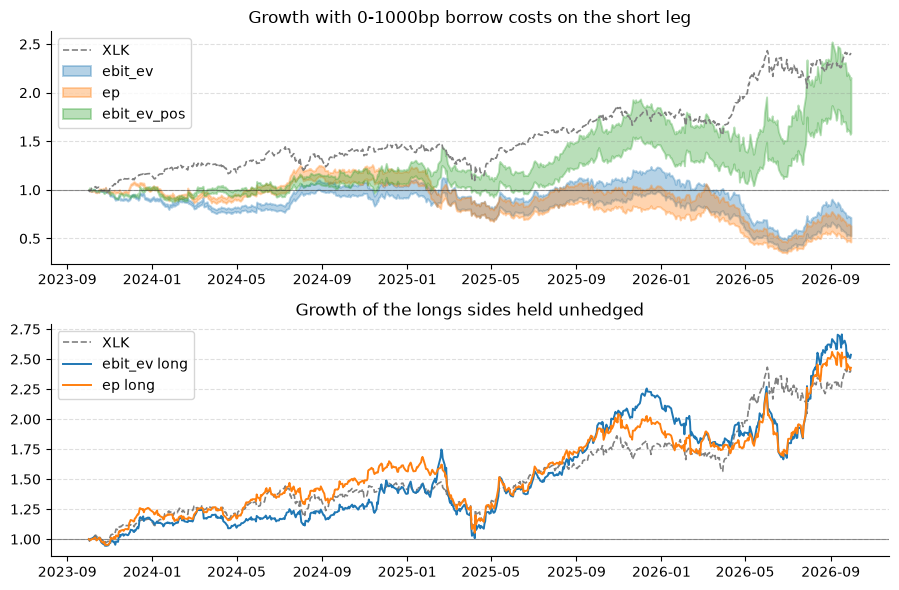

In [199]:
# bought at the same close the first book is, so its opening day is not counted
sector = rets["XLK"].reindex(nav.index).copy()
sector.iloc[0] = 0.0
sector = (1 + sector).cumprod()

fig, axes = plt.subplots(2, 1, figsize=(9, 6))

for ax in axes:
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

axes[0].plot(sector.index, sector, color="gray", ls="--", lw=1.2, label="XLK")
axes[0].axhline(1.0, color="black", lw=0.8, alpha=0.4)
axes[0].grid(axis="y", color="gray", alpha=0.25, linewidth=0.8, linestyle="--")

for screen, color in zip(SCREENS, ("C0", "C1", "C2")):
    free, dear = ((1 + run(screen, bp)[1]).cumprod() for bp in (0, 1000))
    axes[0].fill_between(
        free.index, dear, free, color=color, alpha=0.33, lw=1.4, label=screen
    )


axes[0].set_title(f"Growth with 0-1000bp borrow costs on the short leg")
axes[0].legend(loc="upper left")

axes[1].plot(sector.index, sector, color="gray", ls="--", lw=1.2, label="XLK")
axes[1].axhline(1.0, color="black", lw=0.8, alpha=0.4)
axes[1].grid(axis="y", color="gray", alpha=0.25, linewidth=0.8, linestyle="--")


longs = bench.drop(columns="XLK")

# the positive EBIT restriction cannot alter the long leg
# `.duplicated()` filters it out and proves the equality at the same time.
for col in longs.loc[:, ~longs.T.duplicated()]:
    axes[1].plot(longs.index, (1 + longs[col]).cumprod(), lw=1.4, label=col)

axes[1].set_title("Growth of the longs sides held unhedged")
axes[1].legend(loc="upper left")

fig.tight_layout()
plt.show()

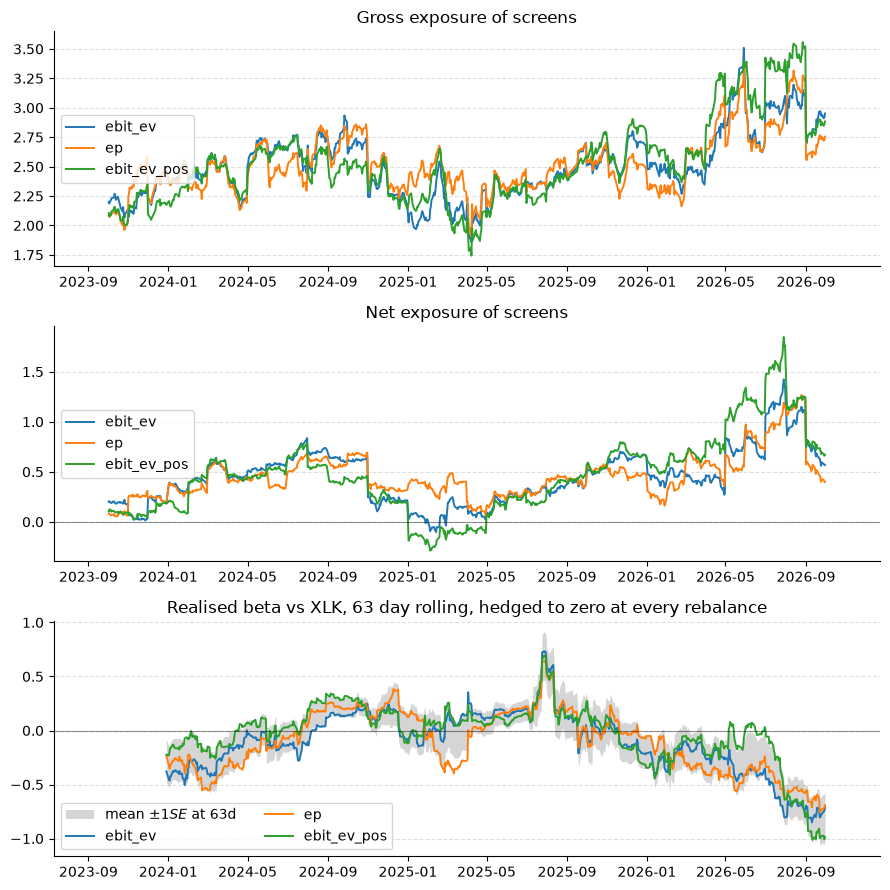

In [211]:
BETA_ROLL = 63

ex = daily.sub(rfd.reindex(daily.index), axis=0)
xs = (rets["XLK"] - rfd).reindex(daily.index)
vx = xs.rolling(BETA_ROLL).var()
roll = ex.rolling(BETA_ROLL).cov(xs).div(vx, axis=0)


se = pd.DataFrame(
    {
        s: np.sqrt(
            (ex[s].rolling(BETA_ROLL).var() - roll[s] ** 2 * vx).clip(lower=0)
            / (vx * BETA_ROLL)
        )
        for s in ex
    }
).mean(axis=1)

centre = roll.mean(axis=1)

fig, axes = plt.subplots(3, 1, figsize=(9, 9))

for ax in axes:
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="y", color="gray", alpha=0.25, linewidth=0.8, linestyle="--")
    ax.set_axisbelow(True)

for name, df in expo.items():
    gross = df.abs().sum(axis=1)
    net = df.sum(axis=1)
    axes[0].plot(gross.index, gross, lw=1.4, label=f"{name}")
    axes[1].plot(net.index, net, lw=1.4, label=f"{name}")

axes[0].set_title("Gross exposure of screens")
axes[0].legend(loc="center left")

axes[1].axhline(0.0, color="black", lw=0.8, alpha=0.4)
axes[1].set_title("Net exposure of screens")
axes[1].legend(loc="center left")

axes[2].fill_between(
    se.index,
    centre - se,
    centre + se,
    color="gray",
    alpha=0.33,
    lw=0,
    zorder=0,
    label=rf"mean $\pm 1 SE$ at {BETA_ROLL}d",
)

for screen, color in zip(SCREENS, ("C0", "C1", "C2")):
    axes[2].plot(roll.index, roll[screen], color=color, lw=1.4, label=screen)

axes[2].axhline(0.0, color="black", lw=0.8, alpha=0.4)
axes[2].set_title(
    f"Realised beta vs XLK, {BETA_ROLL} day rolling, hedged to zero at every rebalance"
)
axes[2].legend(loc="lower left", ncols=2)

for ax in axes:
    quarter = pd.Timedelta(weeks=12)
    ax.set_xlim(roll.index[0] - quarter, roll.index[-1] + quarter)

fig.tight_layout()
plt.show()

# Discussion: borrow cost as a drag on the short book

In this example, borrow costs do not change the fact that the short book itself is a drag on the portfolio. Both the ETF, naive-longs, and positive EBIT cases adress (or eliminate) the short side and end up profitable. We observe that selection influenced heavily by profitability is not very suitable for the IT sector. This is intuitively backed by multiple companies (UBER is a famous example) that operate at a loss for extended periods despite being valued highly by the market.

On the positive EBIT case, where borrow costs apply, the portfolio remains profitable throughout the cost sweep. However we also observe that the maximal tested borrow cost of 1000bp (roughly) halves the return of the portfolio. All else constant, borrow costs are a mathematically provable drag on the short book.
On a separate note, the selection of the short book was provably more inluential on the portfolio than the borrow costs for the given sector. 

Ultimately, borrow costs can be interpreted as a "cost of risk neutralization" for a long-short scheme. Manipulating the beta exposure brigns with it the borrow costs on the short book.